# **Red Wine Quality Prediction Using Machine Learning**

In this project I will use a [wine quality dataset](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009/data). With this dataset I will try and use several different characteristics such as acidity, alcohol content, sulphates etc. to answer the question, **Can the chemical elements of  red wine be used to predict its quality score?**
For this investigation, Linear regression will be used as the initial machine learning approach. The model will be trained using existing measurements and quality scores then evaluated using a separate testing dataset



## Importing Libraries
Here I am importing the libraries needed to load, manipulate and visualise the dataset.

In [73]:
#Samuel Geraghty
#C00298638

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Loading the Dataset
Here the dataset is loaded from the CSV file using pandas

In [74]:
df = pd.read_csv("../data/winequality-red.csv")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Initial Dataset Inspection
Here I check the dataset dimensions to understand the size of the dataset.

In [75]:
print("Dataset dimensions: ", df.shape)

Dataset dimensions:  (1599, 12)


## Handling Duplicate Records
In the wine analysis notebook it was discovered there were 240 duplicates. Using pandas I removed these duplicate records and created a cleaned version of the dataset.

In [76]:
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (1599, 12)
Cleaned dataset: (1359, 12)


## Feature and Target Selection
Here is where I separate the input features and target variables. The input feature(x) contains the 11 chemical properties and target variable(y) contains the wine quality scores.

In [77]:
# X contains all input features (chemical properties)
X = df_clean.drop("quality", axis=1)

# y contains the target variable (wine quality)
y = df_clean["quality"]

In [78]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (1359, 11)
Target: (1359,)


## Training and testing split
The dataset was divided into training and testing datasets. An 80/20 split was selected. This means 80% of the observations are used to train the model while the remaining 20% are used for testing. The training dataset allows the model to learn relationships between the chemical properties and wine quality.

In [79]:
from sklearn.model_selection import train_test_split

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [81]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1087, 11)
Testing features: (272, 11)
Training target: (1087,)
Testing target: (272,)


## Linear Regression Model
linear regression was selected as the initial machine learning model for this investigation. In this project the model uses 11 chemical properties of the wine to estimate its quality score. The model is trained using the training dataset and it calculates coefficients that represent the relationship between each input feature and the predicted quality score.

In [82]:
from sklearn.linear_model import LinearRegression

In [83]:
linear_model = LinearRegression()

In [84]:
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[-0.03,-1. ,-0.1 ,...,-0.8 , 0.85, 0.31]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-16.89
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


## Comparing Actual and Predicted Values
After training the model, predictions were generated using the testing dataset. A dataframe was created to show the actual wine quality scores and the predicted scores.

In [85]:
y_pred = linear_model.predict(X_test)

In [86]:
comparison = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": y_pred
})

comparison.head(10)

,Actual Quality,Predicted Quality
0,5,5.245601
1,6,5.809935
2,7,6.368405
3,5,5.158733
4,4,5.199286
5,7,6.776391
6,5,5.706717
7,5,4.844757
8,6,5.799955
9,5,5.739405


## Model Evaluation
To evaluate the performance of the linear regression model, four regression evaluation metrics were used. The Mean Absolute Error(MAE), Mean Squared Error(MSE), Root Mean Squared Error(RMSE) and R squared score. These metrics provide different ways of measuring the accuracy of the model's predictions.

In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [88]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.5041409053480704
MSE: 0.43100900509009615
RMSE: 0.6565127607976071
R²: 0.39153604990582036


## Actual vs Predicted Visualisation
A scatter plot was created to compare the actual wine quality score with the values predicted by the linear regression model. A diagonal reference line was included to represent perfect predictions, where the predicted score is equal to the actual score. Points closer to this line indicate more accurate predictions while pointers further away represent larger prediction errors.

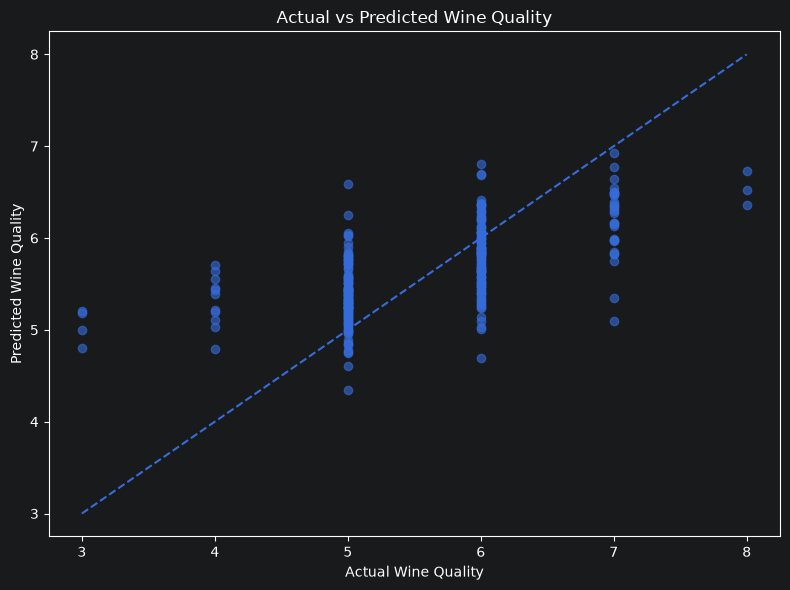

In [89]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")
plt.title("Actual vs Predicted Wine Quality")

plt.tight_layout()
plt.savefig("../results/actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

## Regression coefficient analysis
The coefficients generated by the linear regression model were examined to investigate the relationships between individual chemical properties and predicted wine quality. Each coefficient represents the estimated change in predicted wine quality associated with one unit increase in that feature, while holding the other features constant. Positive coefficients indicate a positive relationship and vice versa.

In [90]:
# Create a DataFrame containing feature names and coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

# Sort coefficients from highest to lowest
coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

print(coefficients)

                 Feature  Coefficient
7                density    22.585222
9              sulphates     0.854602
10               alcohol     0.306154
5    free sulfur dioxide     0.004716
6   total sulfur dioxide    -0.003713
3         residual sugar    -0.003832
0          fixed acidity    -0.028794
2            citric acid    -0.098049
8                     pH    -0.798708
1       volatile acidity    -1.000799
4              chlorides    -2.210790


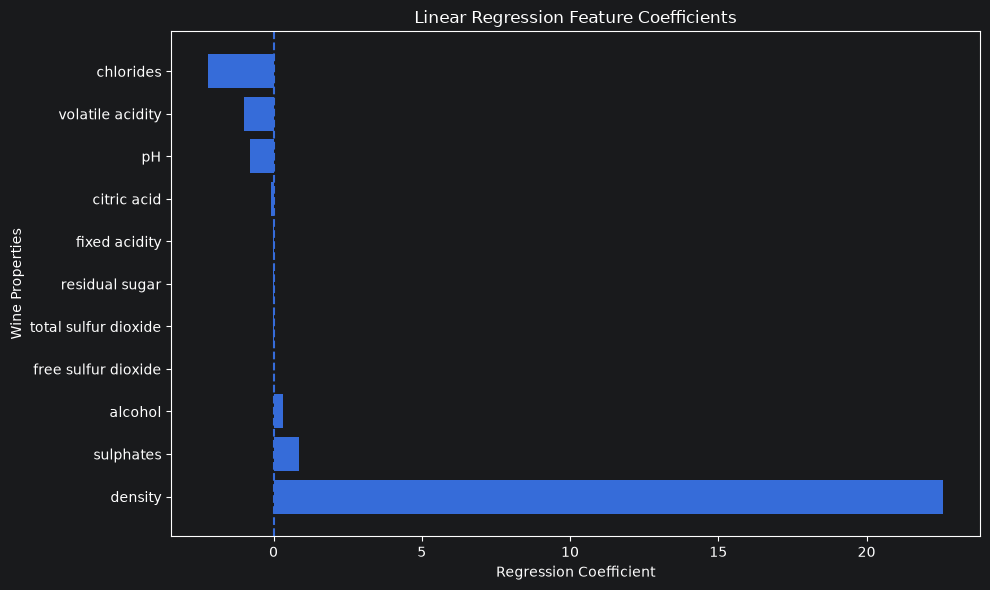

In [91]:
plt.figure(figsize=(10, 6))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.xlabel("Regression Coefficient")
plt.ylabel("Wine Properties")
plt.title("Linear Regression Feature Coefficients")

plt.axvline(x=0, linestyle="--")

plt.tight_layout()
plt.savefig("../results/regression_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

## Residual Analysis
Residual analysis was performed to investigate the differences between the actual wine quality scores and the values predicted by the model. Residuals are calculated by subtracting the predicted value from the actual value. A residual of zero represents a perfect prediction. Positive residuals indicate that the model underestimated the actual quality score, while negative residuals indicate that it overestimated the score. The residual plot displays these differences against the predicted quality scores, with a horizontal reference line at zero.

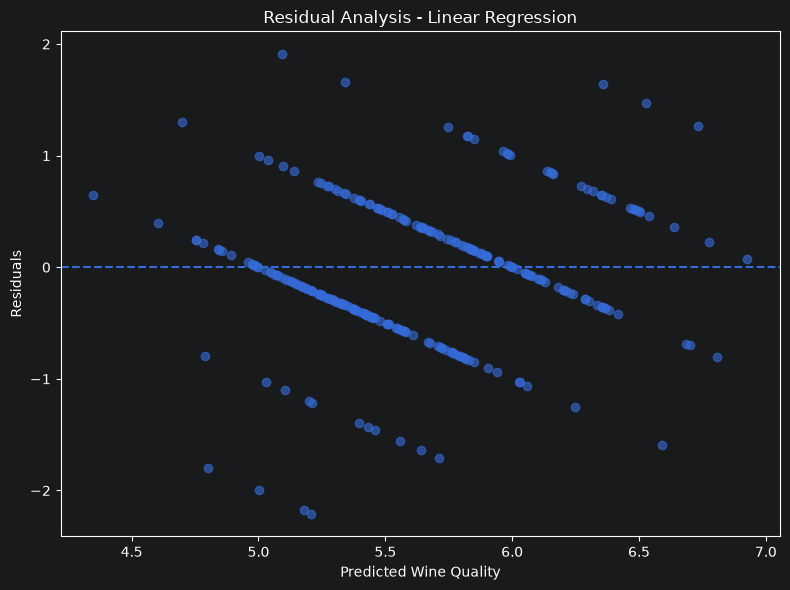

In [92]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.6)

# Reference line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Wine Quality")
plt.ylabel("Residuals")
plt.title("Residual Analysis - Linear Regression")

plt.tight_layout()
plt.savefig("../results/residual_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion

The purpose of this project was to investigate whether the chemical properties of red wine could be used to predict its quality score using machine learning.

The Red Wine Quality dataset was used for this investigation. It originally contained 1,599 observations and 12 columns, consisting of 11 chemical properties and one quality score. During preprocessing, 240 duplicate records were identified and removed, leaving 1,359 observations. No missing values were identified.

A Linear Regression model was selected to predict wine quality based on its chemical properties. The dataset was divided into training and testing sets, using an 80/20 split. The model was trained using the training data and evaluated using the separate testing data.

The model achieved the following results:

- Mean Absolute Error (MAE): 0.5041
- Mean Squared Error (MSE): 0.4310
- Root Mean Squared Error (RMSE): 0.6565
- R² Score: 0.3915

These results indicate that the model achieved a moderate level of predictive performance. The R² score suggests that approximately 39.15% of the variation in wine quality within the test dataset was explained by the model. The MAE indicates that predictions differed from actual quality scores by approximately half a quality point on average.

The actual versus predicted graph showed that predictions were generally concentrated around the middle quality scores. The model struggled more with wines at the lower and higher ends of the quality scale, tending to overestimate lower scores and underestimate higher scores.

The regression coefficient analysis also highlighted relationships between individual chemical properties and predicted wine quality. However, the coefficients must be interpreted carefully because the variables have different measurement scales.

Overall, this investigation demonstrates that Linear Regression can identify relationships between the chemical properties of red wine and its quality score. However, the results also indicate that the model cannot fully explain or predict wine quality using the available features.

For future development, I intend to investigate additional machine learning approaches, explore feature scaling and selection, and compare the predictive performance of different models. This would help determine whether alternative approaches could improve the accuracy of wine quality predictions.

## References
[Wine Quality Dataset](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009/data)
pandas – [Official website](https://pandas.pydata.org/?utm_source=chatgpt.com)
NumPy – [Official website](https://numpy.org/?utm_source=chatgpt.com)
Matplotlib – [Official website](https://matplotlib.org/?utm_source=chatgpt.com)
scikit-learn – [Official website](https://scikit-learn.org/stable/)